# [Lab Session 4](deconvolution.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

In [2]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

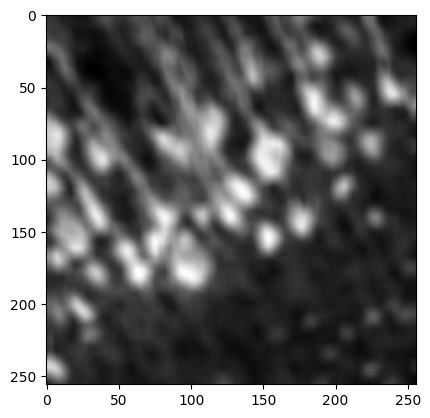

In [3]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

app_psf = conv(img, psf, mode='same',boundary='symm')
plt.imshow(app_psf, 'gray')
plt.show()

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

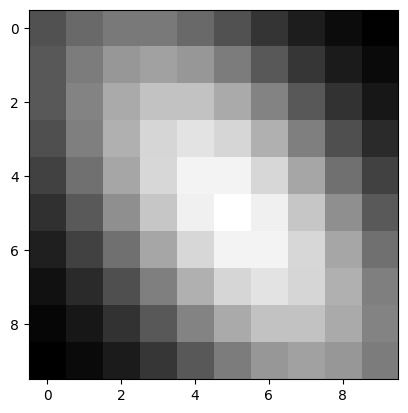

In [4]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

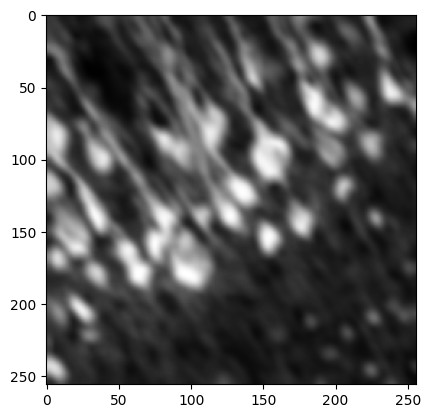

In [5]:
app_gauss = conv(img, create_psf(psf_size), mode='same',boundary='symm')
plt.imshow(app_gauss, 'gray')
plt.show()

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [6]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    

    for i in range(n_iterations):
        img_deconv = img_deconv * conv(image / conv(img_deconv, psf, mode='same', boundary='symm'), np.flip(psf), mode='same', boundary='symm')    
        
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

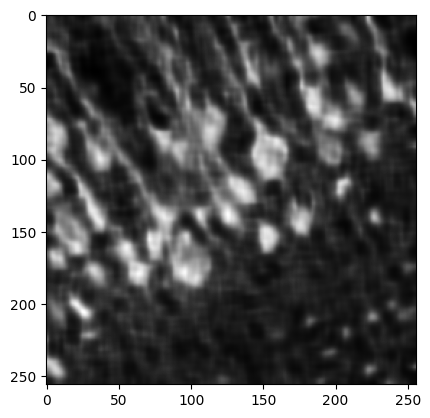

In [7]:
app_RL = richardson_lucy_deconvolution(app_psf, psf, 30)
plt.imshow(app_RL, 'gray')
plt.show()

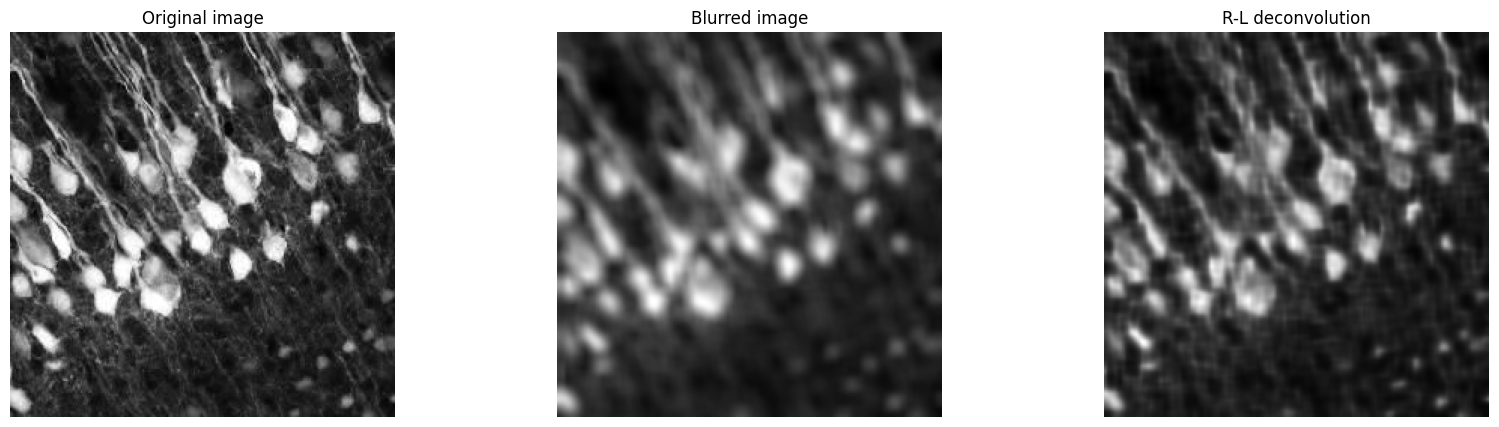

In [ ]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(app_psf, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(app_RL, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [26]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 15
noise = noise / reduce_factor


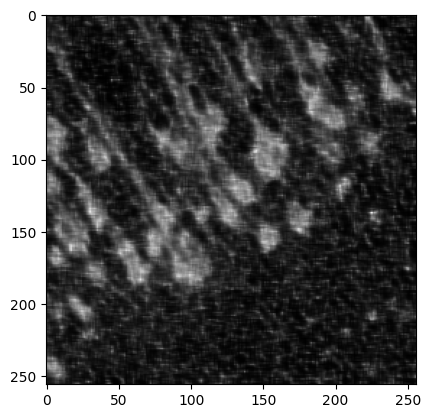

In [27]:
app_wn = app_gauss + noise
app_wn = app_wn.clip(0, 1)

app_wn_RL = richardson_lucy_deconvolution(app_wn, create_psf(psf_size), 30)
plt.imshow(app_wn_RL, 'gray')
plt.show()



**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

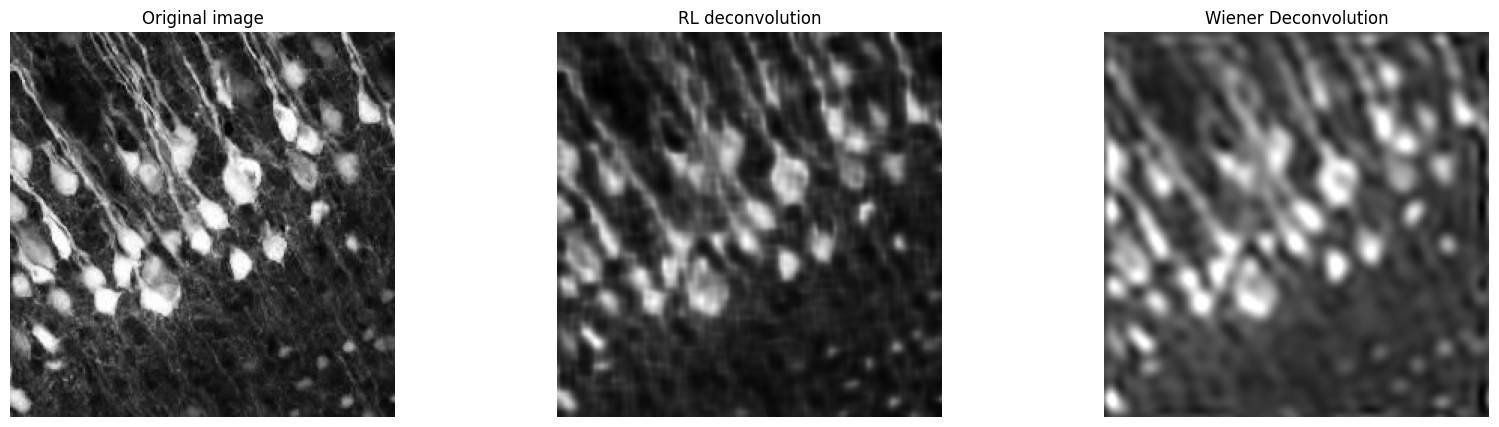

In [40]:
app_wiener =  wiener(app_psf, psf, balance= 1, clip=True)

plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(app_RL, 'gray')
plt.title('RL deconvolution')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(app_wiener, 'gray')
plt.title('Wiener Deconvolution')
plt.show()

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

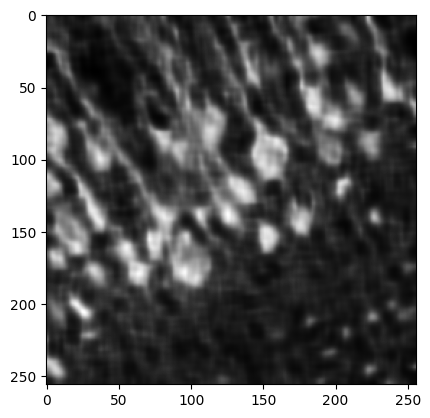

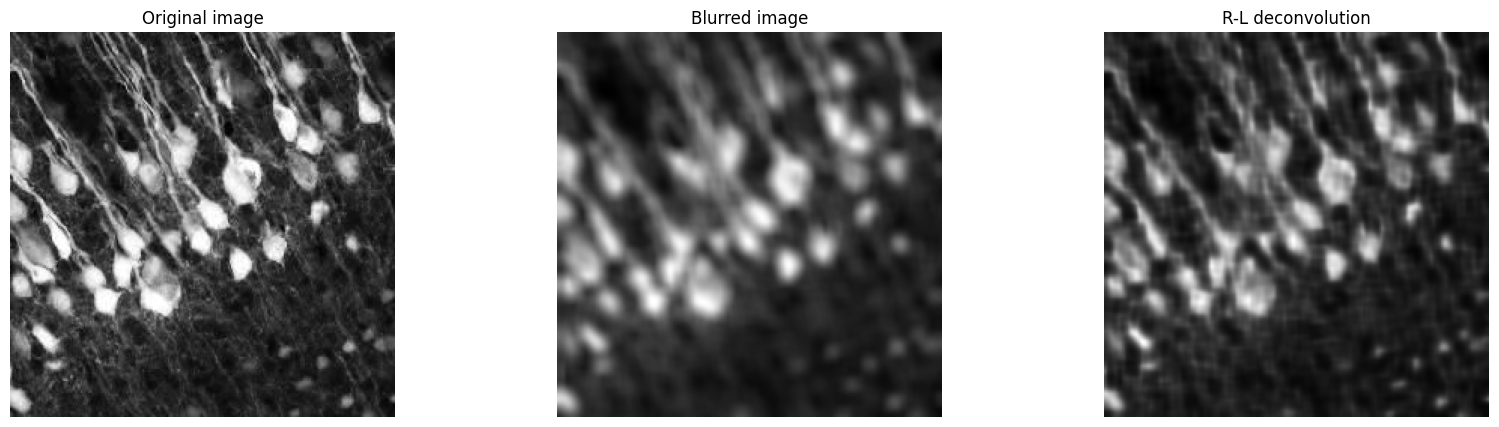

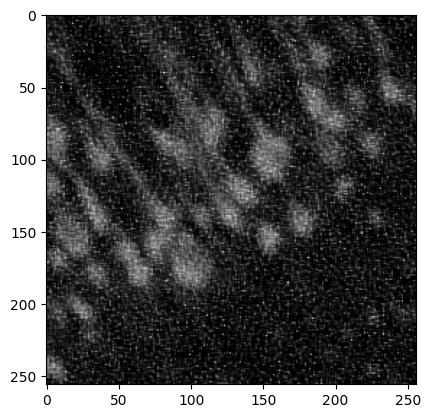

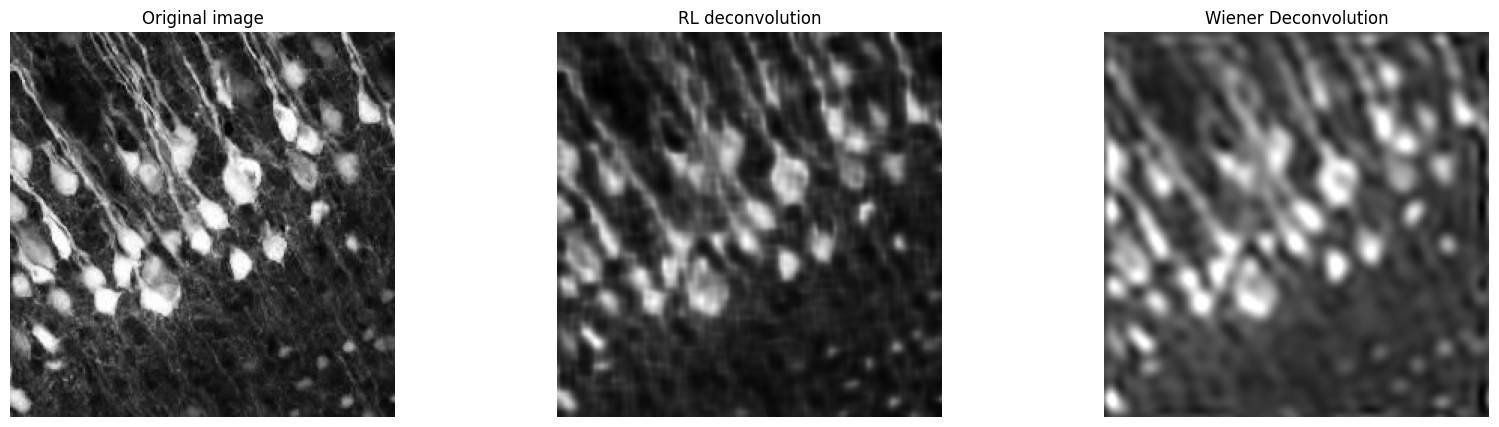

In [46]:
#task 4
psf_size = 5

app_RL = richardson_lucy_deconvolution(app_psf, psf, 30)
plt.imshow(app_RL, 'gray')
plt.show()

plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(app_psf, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(app_RL, 'gray')
plt.title('R-L deconvolution')
plt.show()

#task 5
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 15
noise = noise / reduce_factor

app_wn = app_gauss + noise
app_wn = app_wn.clip(0, 1)

app_wn_RL = richardson_lucy_deconvolution(app_wn, create_psf(psf_size), 30)
plt.imshow(app_wn_RL, 'gray')
plt.show()

#taks 6
app_wiener =  wiener(app_psf, psf, balance= 1, clip=True)

plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(app_RL, 'gray')
plt.title('RL deconvolution')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(app_wiener, 'gray')
plt.title('Wiener Deconvolution')
plt.show()


**[Task 8.]()** Use a wrong PSF to restore the image

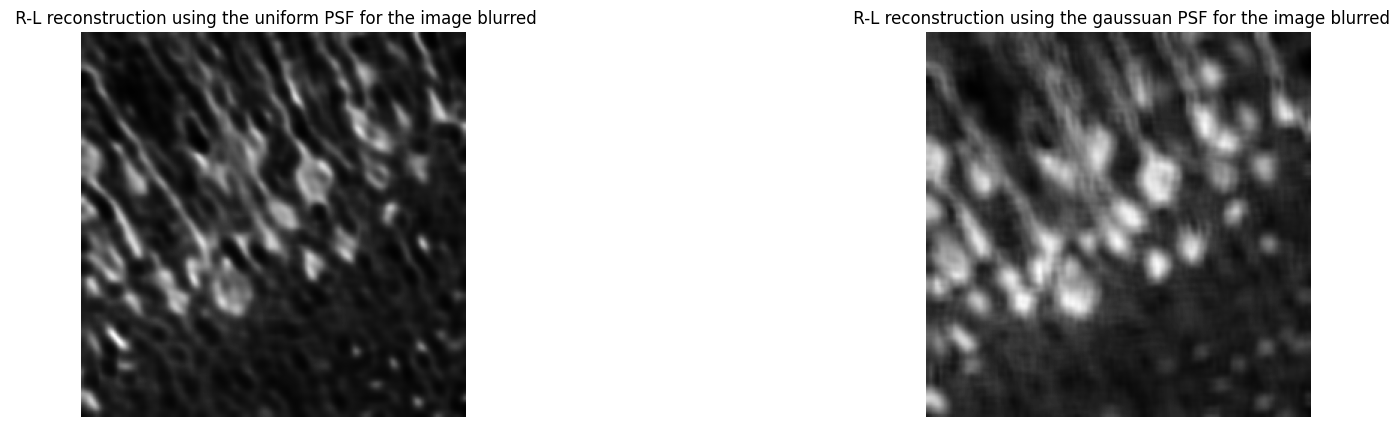

In [ ]:
wrongpsf_gauss = richardson_lucy_deconvolution(app_psf, create_psf(psf_size), 30)
wrongpsf_uniform = richardson_lucy_deconvolution(app_gauss, psf, 30)

plt.figure(figsize=(20,5))
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(wrongpsf_uniform, 'grey')
plt.title(' R-L reconstruction using the uniform PSF for the image blurred')
plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(wrongpsf_gauss, 'grey')
plt.title(' R-L reconstruction using the gaussuan PSF for the image blurred')
plt.show()